# Hospital Operations & Patient Analytics #

**Business problem:** A multispecialty hospital has more patient visits and wants to know where operations are strained: waiting times, costs, satisfaction, readmissions and workload. 

**Data:** 2,000 patient visits (Jan to Dec 2025), 7 departments, 6 cities. File: `hospitaldata.csv` 

## Load the data 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

df=pd.read_csv("hospitaldata.csv")
df

,PatientID,VisitDate,Age,Gender,City,Department,Doctor,Diagnosis,Severity,AdmissionType,Insurance,WaitingTime_Min,LengthOfStay_Days,TreatmentCost,MedicineCost,LabCost,RoomCharges,TotalBill,PaymentMode,DischargeStatus,FollowUpRequired,PatientSatisfaction,Readmitted30Days,BloodGroup,BMI
0,P100001,2025-06-18,71,Male,Salem,Neurology,Dr. G,Fever,Low,Inpatient,No,64,0,8271.06,5813.58,5642.96,0.00,13785.10,Insurance,Recovered,Yes,2,No,O-,23.7
1,P100002,2025-12-25,7,Male,Salem,Oncology,Dr. D,Migraine,Low,Emergency,Yes,140,2,14670.12,4931.02,5457.71,5942.76,24450.20,Cash,Recovered,Yes,1,No,O-,34.8
2,P100003,2025-05-16,8,Male,Madurai,Cardiology,Dr. G,Fever,Medium,Inpatient,Yes,69,2,6374.91,975.73,367.10,4969.60,10624.85,Cash,Referred,Yes,5,No,O-,33.8
3,P100004,2025-09-22,53,Female,Salem,Orthopedics,Dr. E,Asthma,High,Emergency,Yes,60,7,16321.23,8257.83,2581.76,6847.05,27202.05,Cash,Referred,Yes,3,Yes,A-,23.5
4,P100005,2025-07-13,83,Male,Trichy,Orthopedics,Dr. B,Asthma,High,Outpatient,No,128,6,16087.84,2122.50,4365.34,14860.98,26813.06,Card,Recovered,Yes,1,Yes,A-,37.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,P101996,2025-03-25,14,Female,Chennai,ENT,Dr. E,Asthma,Medium,Inpatient,Yes,78,3,14543.17,10597.94,6372.38,1662.12,24238.61,Cash,Under Treatment,No,4,No,A-,33.0
1996,P101997,2025-02-16,36,Male,Coimbatore,ENT,Dr. E,Diabetes,High,Inpatient,No,108,12,9277.59,2445.78,639.96,8123.88,15462.65,Insurance,Under Treatment,No,5,Yes,O+,30.9
1997,P101998,2025-02-19,48,Female,Vellore,Neurology,Dr. F,Fever,Low,Emergency,No,179,1,9114.59,3111.29,6132.19,957.02,15190.98,Cash,Under Treatment,Yes,2,Yes,A+,21.6
1998,P101999,2025-07-28,87,Female,Chennai,ENT,Dr. A,Diabetes,Medium,Emergency,No,78,3,9190.51,9303.38,579.46,4931.67,15317.51,Cash,Under Treatment,No,4,Yes,B+,33.3


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PatientID            2000 non-null   str    
 1   VisitDate            2000 non-null   str    
 2   Age                  2000 non-null   int64  
 3   Gender               2000 non-null   str    
 4   City                 2000 non-null   str    
 5   Department           2000 non-null   str    
 6   Doctor               2000 non-null   str    
 7   Diagnosis            2000 non-null   str    
 8   Severity             2000 non-null   str    
 9   AdmissionType        2000 non-null   str    
 10  Insurance            2000 non-null   str    
 11  WaitingTime_Min      2000 non-null   int64  
 12  LengthOfStay_Days    2000 non-null   int64  
 13  TreatmentCost        2000 non-null   float64
 14  MedicineCost         2000 non-null   float64
 15  LabCost              2000 non-null   float64
 16 

In [3]:
df['VisitDate'] = pd.to_datetime(df['VisitDate'])
df['Month'] = df['VisitDate'].dt.to_period('M').astype(str)
df['Readmitted'] = (df['Readmitted30Days'] == 'Yes').astype(int)
print(df.shape)

(2000, 27)


In [4]:
df.head(5)

,PatientID,VisitDate,Age,Gender,City,Department,Doctor,Diagnosis,Severity,AdmissionType,Insurance,WaitingTime_Min,LengthOfStay_Days,TreatmentCost,MedicineCost,LabCost,RoomCharges,TotalBill,PaymentMode,DischargeStatus,FollowUpRequired,PatientSatisfaction,Readmitted30Days,BloodGroup,BMI,Month,Readmitted
0,P100001,2025-06-18,71,Male,Salem,Neurology,Dr. G,Fever,Low,Inpatient,No,64,0,8271.06,5813.58,5642.96,0.00,13785.10,Insurance,Recovered,Yes,2,No,O-,23.7,2025-06,0
1,P100002,2025-12-25,7,Male,Salem,Oncology,Dr. D,Migraine,Low,Emergency,Yes,140,2,14670.12,4931.02,5457.71,5942.76,24450.20,Cash,Recovered,Yes,1,No,O-,34.8,2025-12,0
2,P100003,2025-05-16,8,Male,Madurai,Cardiology,Dr. G,Fever,Medium,Inpatient,Yes,69,2,6374.91,975.73,367.10,4969.60,10624.85,Cash,Referred,Yes,5,No,O-,33.8,2025-05,0
3,P100004,2025-09-22,53,Female,Salem,Orthopedics,Dr. E,Asthma,High,Emergency,Yes,60,7,16321.23,8257.83,2581.76,6847.05,27202.05,Cash,Referred,Yes,3,Yes,A-,23.5,2025-09,1
4,P100005,2025-07-13,83,Male,Trichy,Orthopedics,Dr. B,Asthma,High,Outpatient,No,128,6,16087.84,2122.50,4365.34,14860.98,26813.06,Card,Recovered,Yes,1,Yes,A-,37.3,2025-07,1


## Check data quality 

In [5]:
df["PatientID"].is_unique

True

In [6]:
# To check is there missing values or duplicate rows?
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Quick statistics for the main number columns
df[['Age', 'WaitingTime_Min', 'LengthOfStay_Days', 'TreatmentCost', 'TotalBill', 'PatientSatisfaction']].describe().round(2)

Missing values: 0
Duplicate rows: 0


,Age,WaitingTime_Min,LengthOfStay_Days,TreatmentCost,TotalBill,PatientSatisfaction
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,45.28,93.61,4.41,13977.29,23295.49,2.99
std,26.10,50.57,3.42,5386.97,8978.28,1.41
min,1.00,5.00,0.00,2175.73,3626.21,1.00
25%,23.00,52.00,2.00,10223.74,17039.56,2.00
50%,45.00,94.00,4.00,13196.62,21994.36,3.00
75%,68.00,138.00,6.00,16947.47,28245.79,4.00
max,90.00,180.00,12.00,35653.88,59423.14,5.00


## Check whether the billing data makes sense 

In [7]:
# 1. Check TotalBill / TreatmentCost relationship
ratio = df['TotalBill'] / df['TreatmentCost']
print("Smallest ratio:", round(ratio.min(), 4))
print("Largest ratio: ", round(ratio.max(), 4))

# 2. Check whether the four cost columns add up to TotalBill
print()
four_costs = df['TreatmentCost'] + df['MedicineCost'] + df['LabCost'] + df['RoomCharges']
matches = (four_costs.round(2) == df['TotalBill'].round(2)).sum()
print("Rows where the four costs add up to TotalBill:", matches)

# 3. How are satisfaction scores spread? (percent of patients for each score)
print()
print("Satisfaction score, % of patients:")
print((df['PatientSatisfaction'].value_counts(normalize=True).sort_index() * 100).round(1))


Smallest ratio: 1.6667
Largest ratio:  1.6667

Rows where the four costs add up to TotalBill: 0

Satisfaction score, % of patients:
PatientSatisfaction
1    19.6
2    21.2
3    20.0
4    19.6
5    19.7
Name: proportion, dtype: float64


## Hospital Overview 

In [8]:
print("Total patients:", len(df))
print("Total revenue: Rs.", round(df['TotalBill'].sum()))
print("Average bill: Rs.", round(df['TotalBill'].mean()))
print("Average treatment cost: Rs.", round(df['TreatmentCost'].mean()))
print("Average waiting time:", round(df['WaitingTime_Min'].mean(), 1), "minutes")
print("Average satisfaction:", round(df['PatientSatisfaction'].mean(), 2), "out of 5")

# Patients per city
print()
print(df['City'].value_counts())


Total patients: 2000
Total revenue: Rs. 46590975
Average bill: Rs. 23295
Average treatment cost: Rs. 13977
Average waiting time: 93.6 minutes
Average satisfaction: 2.99 out of 5

City
Salem         368
Madurai       352
Trichy        342
Vellore       320
Chennai       312
Coimbatore    306
Name: count, dtype: int64


## Number of patients in each department 

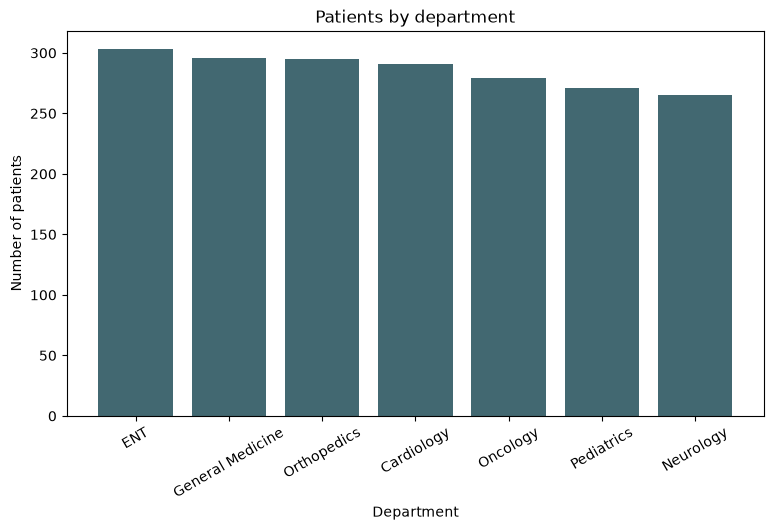

Department
ENT                 303
General Medicine    296
Orthopedics         295
Cardiology          291
Oncology            279
Pediatrics          271
Neurology           265
Name: count, dtype: int64

In [9]:
patients_by_dept = df['Department'].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(patients_by_dept.index, patients_by_dept.values, color='#426871')
plt.title('Patients by department')
plt.xlabel('Department')
plt.ylabel('Number of patients')
plt.xticks(rotation=30)
plt.show()
patients_by_dept


## Payment Modes 

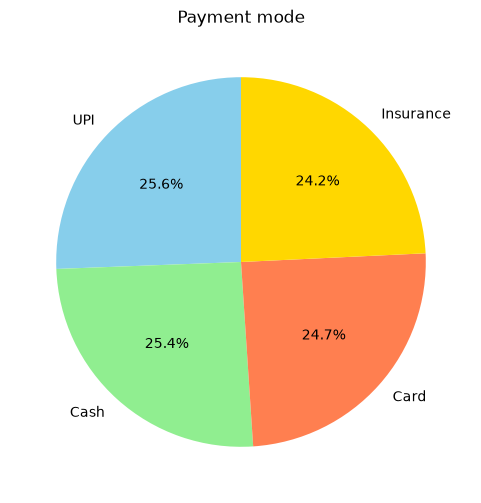

PaymentMode
UPI          512
Cash         509
Card         494
Insurance    485
Name: count, dtype: int64

In [10]:
payment = df['PaymentMode'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(payment.values, labels=payment.index, autopct='%1.1f%%', startangle=90, colors = ['skyblue', 'lightgreen', 'coral', 'gold'])
plt.title('Payment mode')
plt.show()
payment


## Average satisfaction in each department 

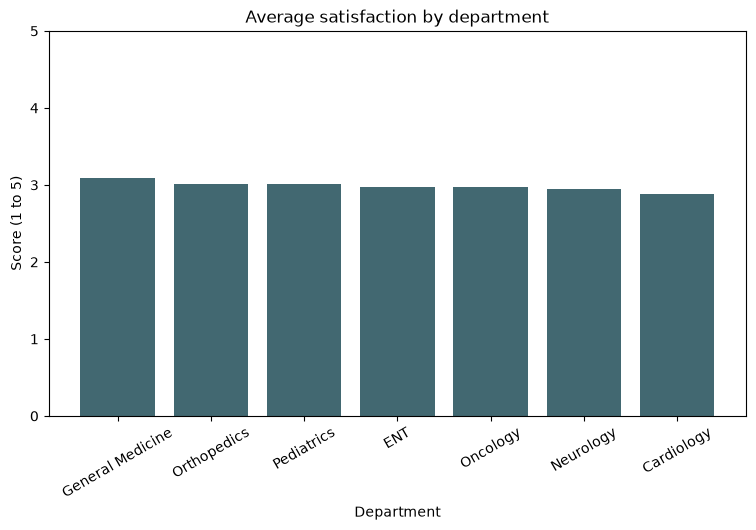

Department
General Medicine    3.09
Orthopedics         3.02
Pediatrics          3.01
ENT                 2.98
Oncology            2.97
Neurology           2.95
Cardiology          2.88
Name: PatientSatisfaction, dtype: float64

In [11]:
satisfaction = df.groupby('Department')['PatientSatisfaction'].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(satisfaction.index, satisfaction.values, color='#426871')
plt.title('Average satisfaction by department')
plt.xlabel('Department')
plt.ylabel('Score (1 to 5)')
plt.ylim(0, 5)
plt.xticks(rotation=30)
plt.show()
satisfaction.round(2)


## Patient visits in each month 

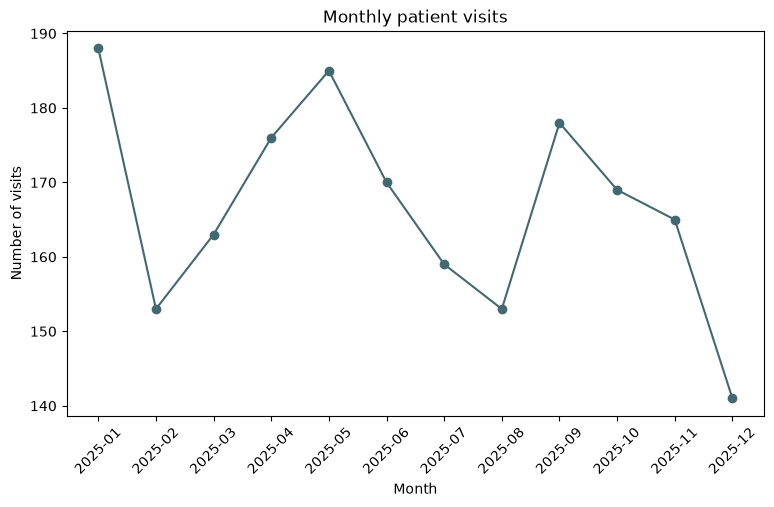

Month
2025-01    188
2025-02    153
2025-03    163
2025-04    176
2025-05    185
2025-06    170
2025-07    159
2025-08    153
2025-09    178
2025-10    169
2025-11    165
2025-12    141
Name: PatientID, dtype: int64

In [12]:
visits = df.groupby('Month')['PatientID'].count()

plt.figure(figsize=(9, 5))
plt.plot(visits.index, visits.values, marker='o', color='#426871')
plt.title('Monthly patient visits')
plt.xlabel('Month')
plt.ylabel('Number of visits')
plt.xticks(rotation=45)
plt.show()
visits

**What this shows:** Patient numbers are even across departments (ENT 303 to Neurology 265) and cities (Salem 368 is the largest). The four payment modes are nearly tied (UPI 512, Cash 509, Card 494, Insurance 485). Satisfaction is 2.88 to 3.09 in every department.

## Which departments readmit patients the most? 

In [13]:
# Calculate readmission rates
dept_readmit = df.groupby('Department')['Readmitted'].mean() * 100
dept_readmit = dept_readmit.sort_values(ascending=False).round(2)

# Readmission rate for the whole hospital
hospital_readmit = df['Readmitted'].mean() * 100
print("Whole hospital:", round(hospital_readmit, 2), "%")
print()
dept_readmit


Whole hospital: 49.75 %



Department
Neurology           55.09
Oncology            50.90
General Medicine    50.34
ENT                 49.83
Cardiology          47.77
Pediatrics          47.60
Orthopedics         47.12
Name: Readmitted, dtype: float64

## Readmission rate by department #

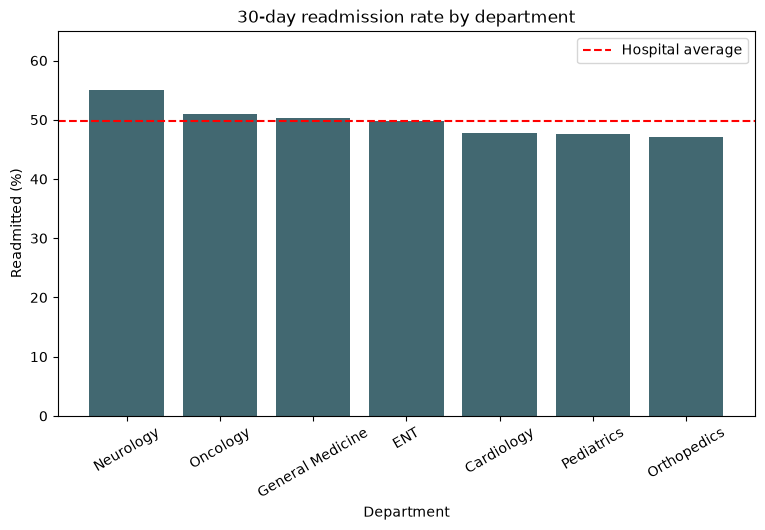

In [14]:
plt.figure(figsize=(9, 5))
plt.bar(dept_readmit.index, dept_readmit.values, color='#426871') 
plt.axhline(hospital_readmit, color='red', linestyle='--', label='Hospital average')
plt.title('30-day readmission rate by department')
plt.xlabel('Department')
plt.ylabel('Readmitted (%)')
plt.ylim(0, 65)
plt.xticks(rotation=30)
plt.legend()
plt.show()

**What this shows:** About half of patients are readmitted within 30 days in every department (47% to 55%), which would be very high for a real hospital. Neurology is highest at 55.1%, but a gap of 5 points on 265 patients could be chance, so it is a lead to check, not proof.

## Does age affect cost, length of stay, or readmission?

In [15]:
def age_group(age):
    if age < 18:
        return '1. Child (0-17)'
    elif age < 40:
        return '2. Young adult (18-39)'
    elif age < 60:
        return '3. Middle age (40-59)'
    else:
        return '4. Senior (60+)'
        
df['AgeGroup'] = df['Age'].apply(age_group)

age_table = pd.DataFrame({
    'Patients': df.groupby('AgeGroup')['PatientID'].count(),
    'Avg bill': df.groupby('AgeGroup')['TotalBill'].mean(),
    'Avg stay (days)': df.groupby('AgeGroup')['LengthOfStay_Days'].mean(),
    'Readmitted %': df.groupby('AgeGroup')['Readmitted'].mean() * 100,
})
age_table.round(2)


,Patients,Avg bill,Avg stay (days),Readmitted %
AgeGroup,,,,
1. Child (0-17),381,22932.13,4.18,47.77
2. Young adult (18-39),501,23540.25,4.49,52.10
3. Middle age (40-59),435,23384.10,4.45,48.05
4. Senior (60+),683,23262.20,4.46,50.22


## Readmission rate by age group #

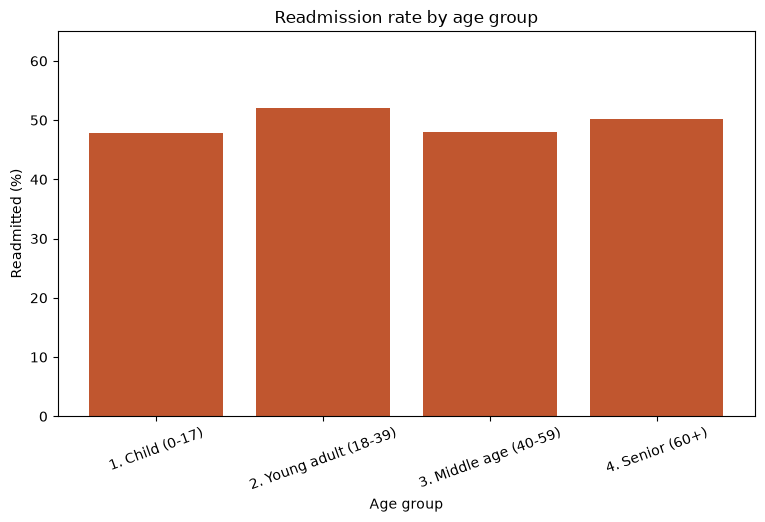

In [16]:
plt.figure(figsize=(9, 5))
plt.bar(age_table.index, age_table['Readmitted %'], color='#C0562F')
plt.title('Readmission rate by age group')
plt.xlabel('Age group')
plt.ylabel('Readmitted (%)')
plt.ylim(0, 65)
plt.xticks(rotation=20)
plt.show()

**What this shows:** Seniors (60+) are the biggest group (683 patients, 34%), but their average bill (about Rs. 23,262) is almost the same as every other group. Young adults have the highest readmission rate (52.1%), yet the spread across age groups is only about 4 points. Age barely changes cost or stay here.

## Does waiting time affect patient satisfaction?

In [17]:
def wait_band(minutes):
    if minutes < 30:
        return '1. Under 30 min'
    elif minutes < 60:
        return '2. 30 to 59 min'
    elif minutes < 120:
        return '3. 60 to 119 min'
    else:
        return '4. 120+ min'

df['WaitBand'] = df['WaitingTime_Min'].apply(wait_band)

wait_table = pd.DataFrame({
    'Patients': df.groupby('WaitBand')['PatientID'].count(),
    'Avg satisfaction': df.groupby('WaitBand')['PatientSatisfaction'].mean(),
})
wait_table.round(2)

,Patients,Avg satisfaction
WaitBand,,
1. Under 30 min,275,3.09
2. 30 to 59 min,313,2.94
3. 60 to 119 min,705,2.98
4. 120+ min,707,2.97


## Satisfaction by waiting-time

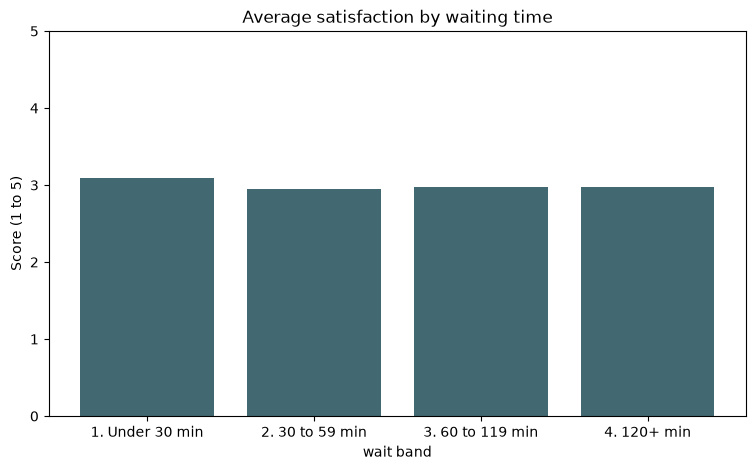

In [18]:
plt.figure(figsize=(9, 5))
plt.bar(wait_table.index, wait_table['Avg satisfaction'], color='#426871')
plt.title('Average satisfaction by waiting time')
plt.xlabel('wait band')
plt.ylabel('Score (1 to 5)')
plt.ylim(0, 5)
plt.show()


## What decides the length of stay?

In [19]:
# Average stay for each severity level
print(df.groupby('Severity')['LengthOfStay_Days'].mean().round(2))

# by department
print()
pd.pivot_table(df, index='Department', columns='Severity',
               values='LengthOfStay_Days', aggfunc='mean').round(2)


Severity
High      8.42
Low       1.08
Medium    3.52
Name: LengthOfStay_Days, dtype: float64



Severity,High,Low,Medium
Department,,,
Cardiology,8.50,1.00,3.45
ENT,8.39,1.17,3.62
General Medicine,8.42,1.12,3.49
Neurology,8.39,1.10,3.54
Oncology,8.51,1.03,3.32
Orthopedics,8.37,1.16,3.58
Pediatrics,8.31,1.01,3.62


**What this shows:** Severity decides the stay: high 8.4 days, medium 3.5, low 1.1, in every department. No department averages more than 5 days.

## Monthly revenue

In [20]:
# Visits and revenue for each month
monthly_visits = df.groupby('Month')['PatientID'].count()
monthly_revenue = df.groupby('Month')['TotalBill'].sum()

monthly = pd.DataFrame({'Visits': monthly_visits, 'Revenue': monthly_revenue})

# Change compared with the previous month, in percent (January has no previous month)
monthly['Change %'] = monthly['Revenue'].pct_change() * 100

# Running total of revenue
monthly['Running total'] = monthly['Revenue'].cumsum()
monthly.round(2)


,Visits,Revenue,Change %,Running total
Month,,,,
2025-01,188,4445171.17,NaN,4445171.17
2025-02,153,3557542.92,-19.97,8002714.09
2025-03,163,3796721.19,6.72,11799435.28
2025-04,176,4013288.41,5.70,15812723.69
2025-05,185,4278999.43,6.62,20091723.12
2025-06,170,4056236.90,-5.21,24147960.02
2025-07,159,3781340.02,-6.78,27929300.04
2025-08,153,3473239.43,-8.15,31402539.47
2025-09,178,4060597.01,16.91,35463136.48


## Revenue per month

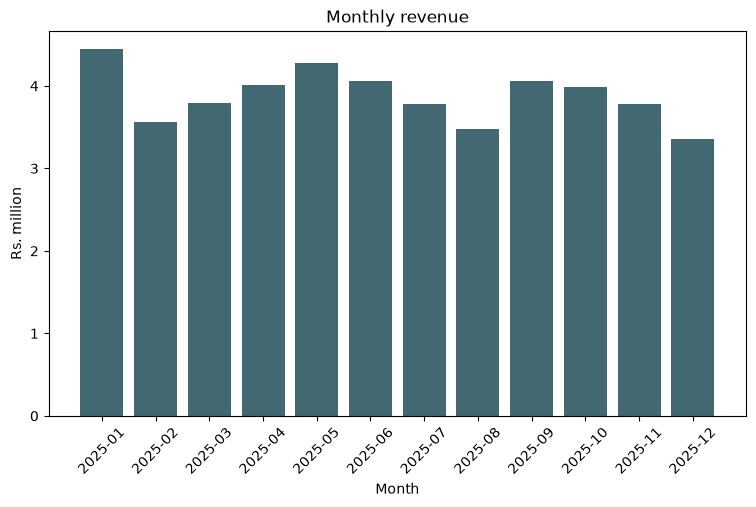

In [21]:
plt.figure(figsize=(9, 5))
plt.bar(monthly.index, monthly['Revenue'] / 1000000, color='#426871')
plt.title('Monthly revenue')
plt.xlabel('Month')
plt.ylabel('Rs. million')
plt.xticks(rotation=45)
plt.show()

**What this shows:** Revenue peaks in January (Rs. 4.45M) and is lowest in December (Rs. 3.36M), a fall of about 24%, following visit numbers. One year of data cannot show whether this is seasonal.

## Is the work spread evenly across doctors?

In [22]:
doctors = pd.DataFrame({
    'Patients': df.groupby('Doctor')['PatientID'].count(),
    'Avg wait (min)': df.groupby('Doctor')['WaitingTime_Min'].mean(),
    'Avg satisfaction': df.groupby('Doctor')['PatientSatisfaction'].mean(),
})

# Each doctor's share of all patients
doctors['Share %'] = doctors['Patients'] / doctors['Patients'].sum() * 100
doctors.sort_values('Patients', ascending=False).round(2)


,Patients,Avg wait (min),Avg satisfaction,Share %
Doctor,,,,
Dr. A,262,94.41,3.00,13.10
Dr. D,259,95.10,2.92,12.95
Dr. B,251,93.45,2.90,12.55
Dr. E,251,95.94,3.04,12.55
Dr. F,251,93.95,3.12,12.55
Dr. C,246,91.91,2.98,12.30
Dr. G,244,92.91,2.93,12.20
Dr. H,236,90.95,2.99,11.80


**What this shows:** Work is balanced: the busiest doctor has 262 patients and the lightest 236. Satisfaction ranges only from 2.90 to 3.12.

## Priority departments: slow and readmitting above average

In [23]:
# Average wait and readmission rate for each department
dept_wait = df.groupby('Department')['WaitingTime_Min'].mean()
dept_readmit = df.groupby('Department')['Readmitted'].mean() * 100

# The hospital-wide averages to compare against
hospital_wait = df['WaitingTime_Min'].mean()
hospital_readmit = df['Readmitted'].mean() * 100

# A small function that gives each department a label
def priority(wait, readmit):
    slow = wait > hospital_wait
    high_readmit = readmit > hospital_readmit
    if slow and high_readmit:
        return 'High priority'
    elif slow or high_readmit:
        return 'Watch'
    else:
        return 'On track'

dept_table = pd.DataFrame({'Avg wait (min)': dept_wait, 'Readmitted %': dept_readmit})
dept_table['Label'] = [priority(w, r) for w, r in zip(dept_table['Avg wait (min)'], dept_table['Readmitted %'])]
dept_table.sort_values('Avg wait (min)', ascending=False).round(2)


,Avg wait (min),Readmitted %,Label
Department,,,
Orthopedics,97.42,47.12,Watch
Cardiology,97.11,47.77,Watch
ENT,96.53,49.83,High priority
Oncology,94.23,50.90,High priority
Neurology,91.95,55.09,Watch
Pediatrics,88.89,47.60,On track
General Medicine,88.64,50.34,Watch


## Waiting time for each department

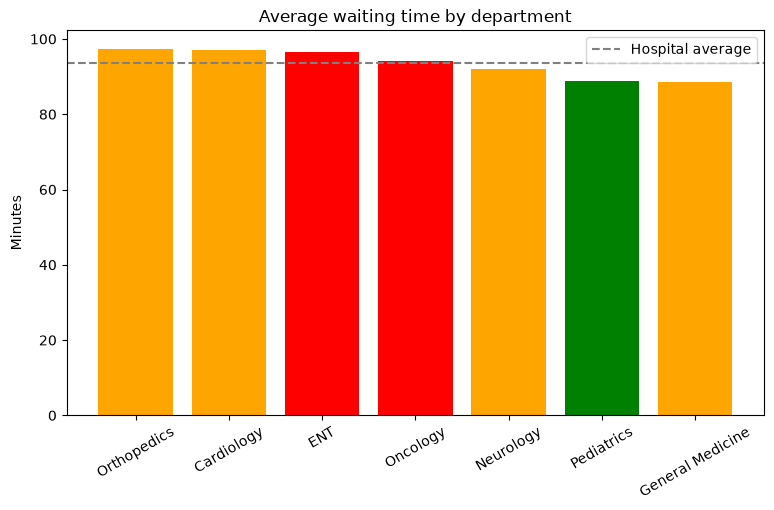

In [24]:
colors = {'High priority': 'red', 'Watch': 'orange', 'On track': 'green'}

# Sort so the longest wait is on the left
chart_table = dept_table.sort_values('Avg wait (min)', ascending=False)
bar_colors = [colors[label] for label in chart_table['Label']]

plt.figure(figsize=(9, 5))
plt.bar(chart_table.index, chart_table['Avg wait (min)'], color=bar_colors)
plt.axhline(hospital_wait, color='grey', linestyle='--', label='Hospital average')
plt.title('Average waiting time by department')
plt.ylabel('Minutes')
plt.xticks(rotation=30)
plt.legend()
plt.show()

**Colour key:** red = high priority (slow and readmitting above average), orange = watch (one of the two), green = on track.

**What this shows:** ENT and Oncology are above average on both measures, but the waits only range from 88.6 to 97.4 minutes, so these labels show where to look first, not a proven problem.

## Findings, recommendations and limits

**Findings**
1. **Readmission is the biggest concern:** 49.75% of patients are readmitted within 30 days, in every department (47% to 55%).
2. **Waiting time is a hospital-wide issue:** the average is 93.6 minutes, and department differences are small.
3. **Waiting time does not explain satisfaction:** the correlation is about -0.01, and scores are near 3 out of 5 everywhere.
4. **Severity, not department, decides length of stay:** 8.4 days (high), 3.5 (medium), 1.1 (low).
5. **Volume, payment mix and doctor workload are all evenly spread.**
6. **Revenue follows visit volume:** it fell from Rs. 4.45M in January to Rs. 3.36M in December.

**Recommendations**
- Audit the readmission process first (discharge checks, follow-up calls), starting with Neurology and Oncology.
- Set one hospital-wide waiting-time target (for example under 60 minutes) and track it monthly.
- Collect better satisfaction data, such as a short survey with comments.
